# Mock Lab 3 — Utility Segmentation & Bank Cross-selling (Clustering + Association Rules)
**เวลา:** 75 นาที · **seed = 1992**
Part A: `data/utilities.csv` — 22 บริษัทไฟฟ้า × 8 ตัวแปร (ข้อมูลเดียวกับสไลด์ clustering p.10)
Part B: `data/bank-data.csv` — ลูกค้า 600 คน · `pep` = ซื้อ Personal Equity Plan หรือไม่

## ตั้งต้น

In [1]:
import warnings; warnings.filterwarnings("ignore", category=UserWarning)   # ซ่อน warning precision=0 ของ baseline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from mlxtend.frequent_patterns import apriori, association_rules
SEED = 1992

## Part A · Clustering (50 คะแนน)

**A1.** เตรียมข้อมูลสำหรับ K-Means (อะไรต้องตัด/ตั้ง role · ต้อง normalize ไหม เพราะอะไร) · **A2.** K-Means k = 2…8 (`n_init=50`) รายงาน WCSS, silhouette, Davies–Bouldin + กราฟ แล้วเลือก k พร้อมเหตุผล

     Fixed_charge    RoR    Cost  Load_factor  Demand_growth     Sales  \
min          0.75   6.40   96.00        49.80          -2.20   3300.00   
max          1.49  15.40  252.00        67.60           9.20  17441.00   
std          0.18   2.24   41.19         4.46           3.12   3549.98   

     Nuclear  Fuel_Cost  
min     0.00       0.31  
max    50.20       2.12  
std    16.79       0.56  


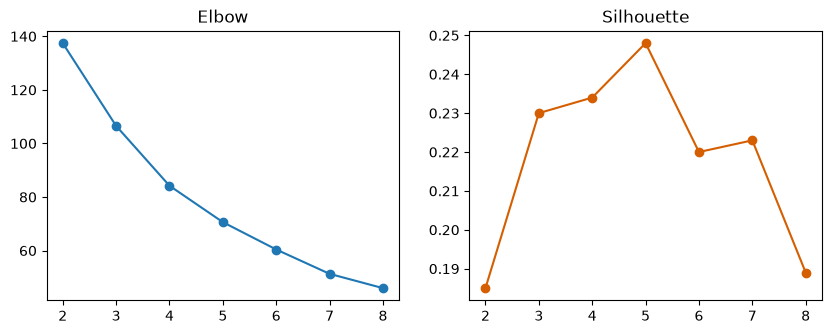

,k,WCSS,silhouette,DB,sizes
0,2,137.450,0.185,1.621,"[15, 7]"
1,3,106.554,0.230,1.367,"[12, 7, 3]"
2,4,84.211,0.234,1.177,"[7, 7, 5, 3]"
3,5,70.616,0.248,1.000,"[7, 6, 5, 3, 1]"
4,6,60.404,0.220,0.989,"[6, 5, 4, 3, 3, 1]"
5,7,51.313,0.223,0.941,"[5, 5, 4, 3, 3, 1, 1]"
6,8,45.979,0.189,0.724,"[6, 5, 5, 2, 1, 1, 1, 1]"


In [2]:
u = pd.read_csv("data/utilities.csv").set_index("Company")      # Company = id → ไม่ใช้คำนวณระยะทาง
print(u.agg(["min", "max", "std"]).round(2))                     # Sales หลักหมื่น vs Fixed_charge ~1
scaler = StandardScaler().fit(u)
Z = pd.DataFrame(scaler.transform(u), index=u.index, columns=u.columns)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    rows.append({"k": k, "WCSS": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                 "DB": davies_bouldin_score(Z, km.labels_), "sizes": sorted(np.bincount(km.labels_), reverse=True)})
ks = pd.DataFrame(rows).round(3)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks["k"], ks["WCSS"], "o-"); ax[0].set_title("Elbow")
ax[1].plot(ks["k"], ks["silhouette"], "o-", color="#D55E00"); ax[1].set_title("Silhouette"); plt.show()
ks

> **✅ เฉลย / การตีความ**
>
> - ตั้ง `Company` เป็น index/id (ไม่ใช้คำนวณ) · ทุกตัวแปรเป็นตัวเลขแล้ว
> - **ต้อง normalize** — Sales อยู่ช่วง 3,300–17,441 ขณะที่ Fixed_charge 0.75–1.49 → ถ้าไม่ scale ระยะทาง Euclidean ≈ ผลต่าง Sales อย่างเดียว
> - WCSS ลดลงเรื่อย ๆ (137 → 46) ไม่มีข้อศอกชัด · silhouette สูงสุดที่ **k = 5 (0.248)** รองลงมา **k = 4 (0.234)** และ k = 3 (0.230) · DB ลดตาม k (k มากขึ้นดูดีขึ้นเสมอ — อย่าใช้ DB ตัวเดียว)
> - k = 5 มีกลุ่มสมาชิกเพียง 1 บริษัท (sizes 7/6/5/3/1) · **เลือก k = 4** (silhouette 0.234 ใกล้ k = 5 แต่ทุกกลุ่มมี ≥ 3 บริษัท ตีความได้) — ถ้าเลือก k = 5 ก็รับได้หากให้เหตุผลด้วย silhouette

**A3.** ด้วย k ที่เลือก: แสดงสมาชิก + centroid (หน่วยเดิม และ z-score) แล้วตั้งชื่อ/อธิบายแต่ละกลุ่ม · **A4.** บริษัทใหม่ Fixed_charge 1.10, RoR 11.0, Cost 160, Load 56, Demand 3.0, Sales 14,000, Nuclear 0, Fuel 0.70 อยู่กลุ่มไหน

In [3]:
km4 = KMeans(n_clusters=4, n_init=50, random_state=SEED).fit(Z)
lab = pd.Series(km4.labels_, index=u.index, name="cluster")
print(lab.groupby(lab).apply(lambda s: ", ".join(s.index)).to_string())
print(u.groupby(lab).mean().round(2).to_string())
print(pd.DataFrame(km4.cluster_centers_, columns=u.columns).round(2).to_string())
new = pd.DataFrame([[1.10, 11.0, 160, 56.0, 3.0, 14000, 0.0, 0.70]], columns=u.columns)
print("บริษัทใหม่ → cluster", km4.predict(pd.DataFrame(scaler.transform(new), columns=u.columns))[0])

cluster
0    Commonwealth, Madison, Northern, Wisconsin, Vi...
1    Boston, NY, Hawaiian, New England, Pacific, Sa...
2    Arizona, Central, Florida, Kentucky, Oklahoma,...
3                                 Idaho, Nevada, Puget
         Fixed_charge    RoR    Cost  Load_factor  Demand_growth     Sales  Nuclear  Fuel_Cost
cluster                                                                                       
0                1.11  11.48  177.20        55.38           3.76   7487.40    38.28       0.77
1                1.07   9.26  178.71        60.54           3.07   5859.43     7.16       1.80
2                1.21  12.49  127.57        55.47           1.71  10163.14     3.21       0.87
3                1.00   8.87  223.33        54.83           6.33  15504.67     0.00       0.57
   Fixed_charge   RoR  Cost  Load_factor  Demand_growth  Sales  Nuclear  Fuel_Cost
0         -0.01  0.34  0.22        -0.37           0.17  -0.41     1.60      -0.61
1         -0.24 -0.67  0.26         

> **✅ เฉลย / การตีความ**
>
> (เลข cluster อาจสลับได้ — ดูที่สมาชิก)
> | กลุ่ม | สมาชิก | ลักษณะ (z ของ centroid) | ชื่อ |
> |---|---|---|---|
> | A | Idaho, Nevada, Puget | Sales +1.90 · Cost +1.37 · Demand +1.02 · Fuel −0.99 | ขายมาก โตเร็ว เชื้อเพลิงถูก |
> | B | Boston, NY, Hawaiian, New England, Pacific, San Diego, United | Fuel_Cost +1.28 · Load +0.82 · Sales −0.88 | เชื้อเพลิงแพง ขายน้อย |
> | C | Commonwealth, Madison, Northern, Wisconsin, Virginia | Nuclear +1.60 | พึ่งพานิวเคลียร์ |
> | D | Arizona, Central, Florida, Kentucky, Oklahoma, Southern, Texas | Cost −1.01 · RoR +0.80 | ต้นทุนต่ำ ผลตอบแทนดี |
> **A4.** บริษัทใหม่ (Sales 14,000 ค่อนข้างสูง, Cost/Fuel ต่ำ, ไม่มี nuclear) → ตกกลุ่ม **D "ต้นทุนต่ำ ผลตอบแทนดี"** (ต้อง transform ด้วย scaler ตัวเดิมก่อน predict)

**A5.** วาดกลุ่มบน PCA 2 มิติ (ใส่ชื่อบริษัท) และประเมิน cohesion / separation จากภาพ

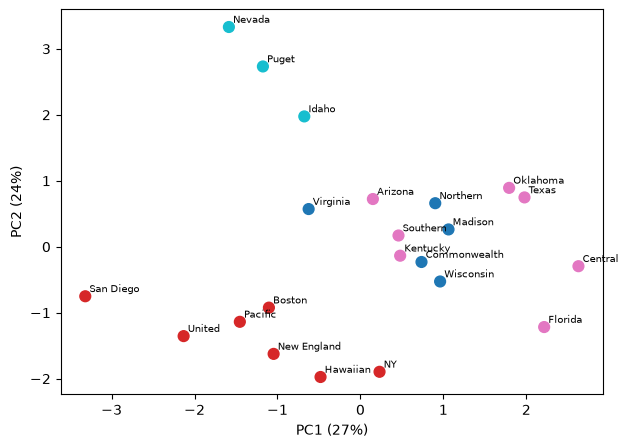

PC1+PC2 = 0.509


In [4]:
pca = PCA(n_components=2).fit(Z); P = pca.transform(Z)
plt.figure(figsize=(7, 5))
plt.scatter(P[:, 0], P[:, 1], c=km4.labels_, cmap="tab10", s=60)
for name, (a, b) in zip(u.index, P):
    plt.annotate(name, (a, b), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.show()
print("PC1+PC2 =", pca.explained_variance_ratio_[:2].sum().round(3))

> **✅ เฉลย / การตีความ**
>
> 2 PC เก็บความแปรปรวนได้เพียง **50.9%** (8 มิติ → 2) จึงเห็นภาพบางส่วนเท่านั้น · กลุ่ม Idaho/Nevada/Puget แยกออกจากกลุ่มอื่นชัด (**separation ดี**) · กลุ่มเชื้อเพลิงแพงกระจายกว้าง (**cohesion ต่ำ** — San Diego, NY อยู่ขอบ) · ภาพสอดคล้องกับ silhouette ~0.23 (กลุ่มซ้อนกันบางส่วน)

## Part B · Association Rules (50 คะแนน)

**B1.** เลือก attribute ที่เหมาะกับการหากฎ (อธิบายว่าตัดอะไรเพราะอะไร) · discretize `age`, `income` เป็น 3 ช่วง equal frequency, `children` เป็น 0 / 1-2 / 3+ · แปลงเป็นตาราง item (True/False)

In [5]:
b = pd.read_csv("data/bank-data.csv")
print(b["sex"].value_counts(normalize=True).round(3).to_dict(), b["current_act"].value_counts(normalize=True).round(3).to_dict())
basket = pd.DataFrame({
    "age": pd.qcut(b["age"], 3, labels=["YOUNG", "MIDDLE", "SENIOR"]),
    "income": pd.qcut(b["income"], 3, labels=["LOW", "MID", "HIGH"]),
    "children": pd.cut(b["children"], [-1, 0, 2, 10], labels=["0", "1-2", "3+"]),
})
for c in ["married", "car", "save_act", "mortgage", "pep"]:
    basket[c] = b[c]
items = pd.get_dummies(basket, prefix_sep="=").astype(bool)
print(items.shape)
items.head(3)

{'FEMALE': 0.5, 'MALE': 0.5} {'YES': 0.758, 'NO': 0.242}
(600, 19)


,age=YOUNG,age=MIDDLE,age=SENIOR,income=LOW,income=MID,income=HIGH,children=0,children=1-2,children=3+,married=NO,married=YES,car=NO,car=YES,save_act=NO,save_act=YES,mortgage=NO,mortgage=YES,pep=NO,pep=YES
0,False,True,False,True,False,False,False,True,False,True,False,True,False,True,False,True,False,False,True
1,False,True,False,False,True,False,False,False,True,False,True,False,True,True,False,False,True,True,False
2,False,False,True,True,False,False,True,False,False,False,True,False,True,False,True,True,False,True,False


> **✅ เฉลย / การตีความ**
>
> ตัด **id** (ไม่ซ้ำทุกแถว = ไม่มีวันเป็น frequent item) · **region** (4 ค่า ทำให้ support กระจายจนกฎน้อย) · **sex** (50/50 พอดี ไม่ให้ข้อมูล) · **current_act** (YES 75.8% เกือบคงที่ → ไปโผล่ในกฎเกือบทุกข้อโดยไม่มีความหมาย)
> discretize: equal frequency เพราะ income **เบ้ขวา** (equal width ช่วง HIGH จะแทบว่าง) · children ใช้ช่วงตามความหมาย
> ได้ **600 transaction × 19 item** (แต่ละ item = attribute=value)

**B2.** Apriori min_support = 0.10 · rules min_confidence = 0.70 · แสดง 5 กฎที่ทำนาย `pep=YES` เรียงตาม lift · ตีความกฎอันดับ 1 ครบ support/confidence/lift + ข้อเสนอธุรกิจ · **B3.** ถ้าเพิ่ม min_support เป็น 0.20 เกิดอะไรขึ้น

In [6]:
def pep_rules(min_support):
    freq = apriori(items, min_support=min_support, use_colnames=True)
    rules = association_rules(freq, metric="confidence", min_threshold=0.70)
    pep = rules[rules["consequents"] == frozenset({"pep=YES"})].sort_values("lift", ascending=False)
    print(f"min_support={min_support}: itemsets={len(freq)} rules={len(rules)} rules→pep=YES: {len(pep)}")
    return pep[["antecedents", "support", "confidence", "lift"]].round(3)

print("P(pep=YES) =", round(items["pep=YES"].mean(), 3))
display(pep_rules(0.10).head(5))
pep_rules(0.20)

P(pep=YES) = 0.457
min_support=0.1: itemsets=413 rules=215 rules→pep=YES: 8


,antecedents,support,confidence,lift
113,"frozenset({age=SENIOR, income=HIGH, children=1...",0.105,0.940,2.059
155,"frozenset({income=HIGH, mortgage=NO, children=...",0.103,0.939,2.057
152,"frozenset({income=HIGH, children=1-2, save_act...",0.125,0.926,2.028
56,"frozenset({income=HIGH, children=1-2})",0.145,0.926,2.027
37,"frozenset({age=SENIOR, children=1-2})",0.125,0.798,1.747


min_support=0.2: itemsets=95 rules=26 rules→pep=YES: 0


,antecedents,support,confidence,lift


> **✅ เฉลย / การตีความ**
>
> P(pep=YES) = **0.457** · min_support 0.10 → 413 itemsets · 215 rules · ทำนาย pep=YES **8 กฎ** · 4 อันดับแรก:
> | antecedents | support | confidence | lift |
> |---|---|---|---|
> | age=SENIOR, income=HIGH, children=1-2 | 0.105 | 0.940 | **2.059** |
> | income=HIGH, children=1-2, mortgage=NO | 0.103 | 0.939 | 2.057 |
> | save_act=YES, income=HIGH, children=1-2 | 0.125 | 0.926 | 2.028 |
> | income=HIGH, children=1-2 | 0.145 | 0.926 | 2.027 |
> **กฎอันดับ 1:** 10.5% ของลูกค้าทั้งหมดเป็นผู้สูงวัย รายได้สูง มีลูก 1–2 คน **และ** ซื้อ PEP · ในกลุ่มนี้ **94.0%** ซื้อ PEP · สูงกว่าอัตราซื้อทั่วไป (45.7%) **2.06 เท่า**
> **ข้อเสนอ:** เจาะกลุ่ม "รายได้สูง + มีลูก 1–2 คน" (ปรากฏในทุกกฎอันดับต้น) ด้วยแคมเปญ PEP เพื่อการศึกษาลูก/เกษียณ
> **B3.** min_support 0.20 → **ไม่มีกฎที่ทำนาย pep=YES เลย** — กลุ่มที่สัมพันธ์กับ PEP สูงเป็น **กลุ่มเฉพาะ (~10–15% ของลูกค้า)** ตั้ง support สูงเกินจึงตัดกฎที่มีประโยชน์ทิ้ง · ตั้งต่ำเกินได้กฎมากเกินและไม่น่าเชื่อถือ → เลือก support ตามขนาดกลุ่มเป้าหมายที่ธุรกิจยอมรับได้

## ทำซ้ำใน RapidMiner — เฉลย `solution_rapidminer.rmp`
- **Part A:** `Read CSV` → `Set Role` (Company = id) → `Normalize` (Z) → `k-Means` (k = 4, max runs 50, good start values) → `Cluster Distance Performance` (Davies Bouldin) · elbow: ครอบด้วย `Optimize Parameters (Grid)` + `Log`
- **Part B:** `Read CSV` → `Select Attributes` (ตัด id, region, sex, current_act) → `Discretize by Frequency` (age, income: 3 bins) → `Discretize by User Specification` (children) → `Nominal to Binominal` → `FP-Growth` (min support 0.1) → `Create Association Rules` (min confidence 0.7)